In [22]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits

In [23]:
#Loading the file
file = "NGC0628.phot.1.fits"

#Reading in the file
with fits.open(file) as fits:
    fits.info()
    header = fits[0].header
    image = fits[0].data.astype(float)

#Printing image shape and headers. We will later print important headers
print("Image shape:", image.shape)
print(header)

Filename: NGC0628.phot.1.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU    1691   (1535, 1853)   float32   
Image shape: (1853, 1535)
SIMPLE  =                    T / Fits standard                                  BITPIX  =                  -32 / Bits per pixel                                 NAXIS   =                    2 / Number of axes                                 NAXIS1  =                 1535 / Axis length                                    NAXIS2  =                 1853 / Axis length                                    EXTEND  =                    T / File may contain extensions                    ORIGIN  = 'NOAO-IRAF FITS Image Kernel July 2003' / FITS file originator        DATE    = '2009-08-21T14:26:04' / Date FITS file was generated                  IRAF-TLM= '2010-04-09T13:58:08' / Time of last modification                     OBJECT  = 'NGC628  '           / Name of the object observed                    CREATOR = 'S18

In [25]:
#From the previous output we get header info, printing important headers

print("Object:", header.get("OBJECT"))
print("Telescope:", header.get("TELESCOP"))
print("Instrument:", header.get("INSTRUME"))
print("Data units:", header.get("BUNIT"))
print("Image width:", header.get("NAXIS1"), "pixels")
print("Image height:", header.get("NAXIS2"), "pixels")

Object: NGC628
Telescope: Spitzer
Instrument: IRAC
Data units: MJy/sr
Image width: 1535 pixels
Image height: 1853 pixels


In [29]:
#Finding pixel values
y, x = np.array(image.shape) // 2
#Printing pixel value at the center
print("x =", x)
print("y =", y)
print(image[y, x])
#printing a small region of pixels
print(image[y-5:y+5, x-5:x+5]) 

x = 767
y = 926
0.9152104258537292
[[0.26047489 0.25906751 0.25831428 0.27615368 0.26425761 0.22491981
  0.22140232 0.21057937 0.21048161 0.2070768 ]
 [0.2918663  0.32926306 0.37397814 0.38483867 0.31350896 0.27503791
  0.25255752 0.23998651 0.22807203 0.21378823]
 [0.35646605 0.43229192 0.50676668 0.56951463 0.5190801  0.39906445
  0.29511768 0.26109341 0.25137496 0.24629588]
 [0.42539862 0.65089715 0.78658837 0.78820843 0.73362267 0.56840914
  0.41023016 0.3010743  0.27114382 0.25780219]
 [0.51697117 0.74295861 1.01315808 1.29727244 1.18022287 0.76264876
  0.51940614 0.36667833 0.34951866 0.29994199]
 [0.55987418 0.80261141 1.15924406 1.45277572 1.30888569 0.91521043
  0.63347977 0.47041613 0.40027592 0.36696115]
 [0.45458934 0.69737065 0.94861156 1.12148714 1.12474501 0.89101994
  0.61926198 0.49168295 0.455551   0.42924625]
 [0.36356121 0.51012659 0.69231373 0.87894952 0.80046535 0.6621207
  0.55230987 0.48925829 0.45863572 0.43045479]
 [0.34263125 0.39761862 0.47759932 0.62184441 

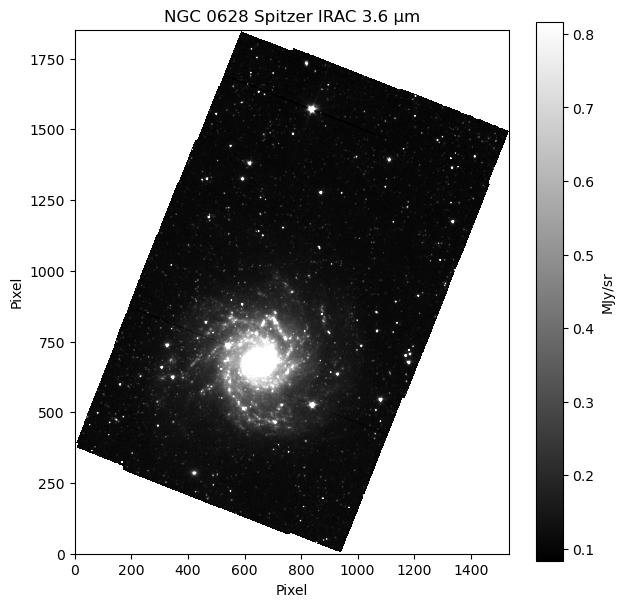

In [40]:
#Plotting the data
plt.figure(figsize=(7, 7))
#Displaying the image with min and max displayed intensities
plt.imshow(image, origin="lower", cmap="gray", vmin=np.nanpercentile(image, 1),
           vmax=np.nanpercentile(image, 99))
#Adding a colorbar with units MJy/sr
plt.colorbar(label=header.get("BUNIT"))
plt.title("NGC 0628 Spitzer IRAC 3.6 μm")
plt.xlabel("Pixel")
plt.ylabel("Pixel")
plt.show()